![Banner](../images/09_05_banner_rs_hyperspect.png)


# Deep Learning for Hyperspectral Classification

Deep networks learn spectral and spatial features directly from labelled pixels. This notebook trains
four architectures from `geolattice.rsense.dl.hyperspectral` on the Pavia Centre benchmark (a 1D spectral
CNN, a 3D CNN, HybridSN and a spectral transformer) and compares them with a random forest and a
spectral angle baseline. Training and test pixels come from separate spatial blocks, the training set
is deliberately small, and the result is mapped over the whole city with per pixel confidence.


## Overview

### Why deep learning for hyperspectral data

Classic classifiers (maximum likelihood, SVM, random forest) see each pixel's spectrum on its own.
Neighbouring pixels carry information too (texture, shape, context: a roof next to a street), and
the spectrum has local structure (absorption features) that convolutions can detect. Deep networks
learn both from data:

| Model | Input | Idea |
|---|---|---|
| 1D CNN | One spectrum | Convolutions along wavelength learn absorption features |
| 3D CNN | A small cube (bands by p by p pixels) | Joint spectral and spatial kernels |
| HybridSN (Roy et al. 2020) | A small cube of 15 to 30 PCA components | 3D convolutions for spectral and spatial features, then a 2D convolution |
| Spectral transformer (SpectralFormer style, Hong et al. 2022) | A spectrum split into groups of bands | Self attention between band groups |

### Pitfalls

- **Spatial leakage.** Neighbouring pixels are almost identical, and patches around neighbouring
  pixels overlap. If training and test pixels are drawn at random from the same areas, the test
  measures memorisation, and published accuracies near 100 percent on benchmarks are often inflated
  this way. Splitting by spatial **blocks** gives honest numbers.
- **Few labels.** Field labels are expensive; networks with many parameters overfit small training
  sets, so augmentation (rotations and flips of patches), dropout, weight decay and validation based
  early stopping matter.
- **Class imbalance.** Benchmarks are dominated by a few classes; overall accuracy then hides poor
  performance on rare ones, so per class scores and kappa are reported.
- **Transfer.** A network trained on one sensor, date or city rarely works on another without
  retraining.


## Deep Learning with GeoLattice

`geolattice.rsense.dl.hyperspectral` provides `block_split` (spatial train and test split), the
`HSIPatchDataset` (patches or spectra around labelled pixels, normalised, with optional
augmentation), the four model constructors, `train_hsi_classifier` (AdamW, cosine learning rate,
best validation weights), `evaluate` and `predict_hsi_map`. Models need PyTorch; a GPU is used
automatically when available.

### Learning objectives

1. Split labelled pixels into spatially separate training and test blocks.
2. Build patch and spectrum datasets with consistent normalisation.
3. Train and compare 1D CNN, 3D CNN, HybridSN and spectral transformer models against a random forest
   and SAM.
4. Read per class scores and a confusion matrix, not only overall accuracy.
5. Map the whole scene with the best model and inspect its confidence.

### Data

| Dataset | Content |
|---|---|
| `Pavia/pavia.npy` | Pavia Centre, ROSIS, 1096 by 715 pixels, 102 bands (430 to 860 nm), 1.3 m |
| `Pavia/Pavia_gt.mat` | Ground truth for 9 classes (148,152 labelled pixels), from the Grupo de Inteligencia Computacional of the University of the Basque Country |

### Contents

- Setup
- Data and a spatial split
- Baselines: SAM and random forest
- Datasets and training
- Comparing the models
- Per class results
- Mapping the city
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import time  # timing
import scipy.io  # ground truth
import torch  # deep learning
from torch.utils.data import DataLoader, Subset  # batches
from sklearn.ensemble import RandomForestClassifier  # baseline
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix  # scores
from geolattice.rsense.dl import hyperspectral as dlh  # hyperspectral deep learning

torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

GeoLattice 0.3.49


device: cuda NVIDIA RTX A5500 Laptop GPU


## Data and a spatial split


1800 training, 450 validation and 56,425 test pixels


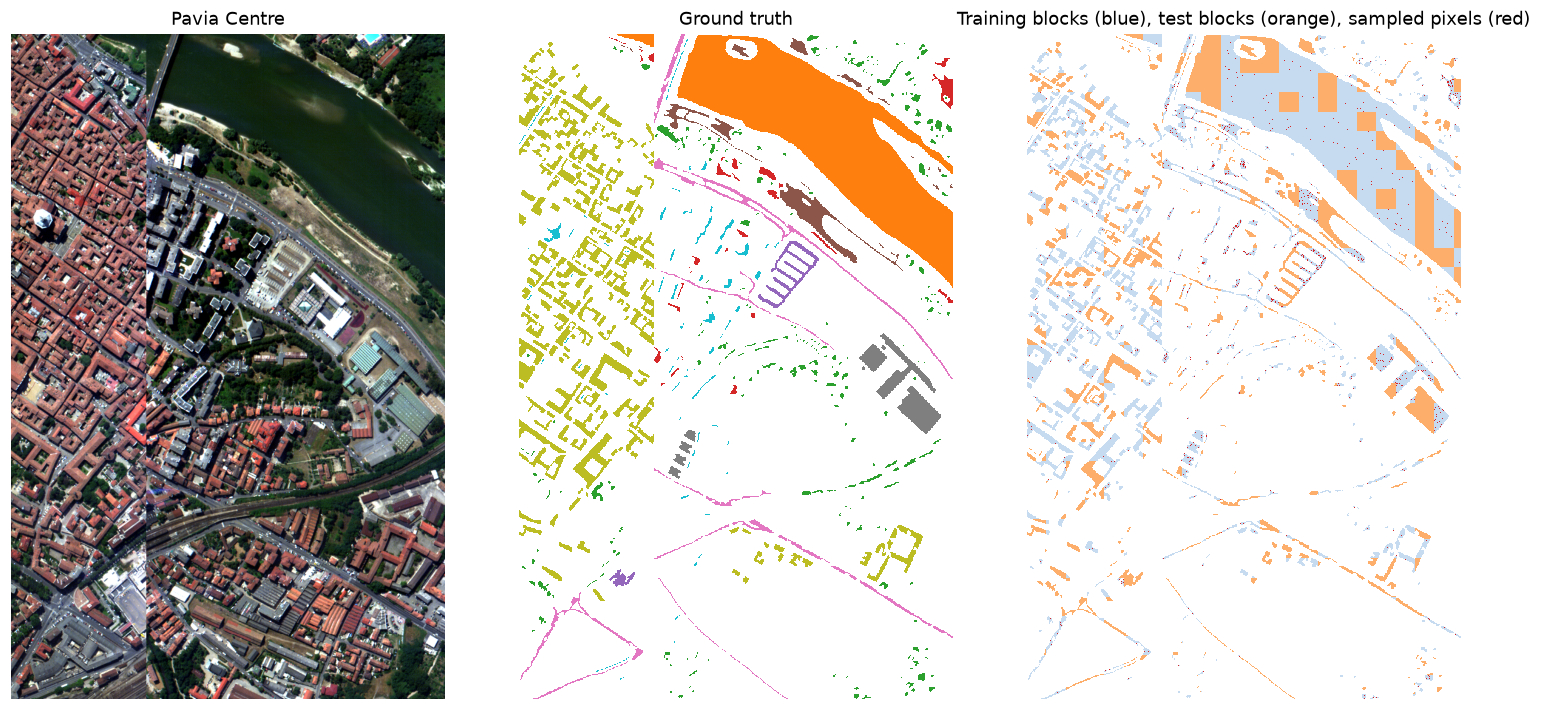

,train,validation,test
water,200,50,21810
trees,200,50,3004
meadows,200,50,1746
self-blocking bricks,200,50,1540
bare soil,200,50,3145
asphalt,200,50,4221
bitumen,200,50,3375
tiles,200,50,16525
shadows,200,50,1059


In [2]:
arr = np.load(DATA / "Pavia/pavia.npy")
pavia = hs.as_cube(arr.transpose(2, 0, 1).astype("float32") / 10000, np.linspace(430, 860, arr.shape[2]))
gt = np.ascontiguousarray(scipy.io.loadmat(DATA / "Pavia/Pavia_gt.mat")["pavia_gt"], dtype=int)  # 0 = unlabelled; C order
NAMES = ["water", "trees", "meadows", "self-blocking bricks", "bare soil", "asphalt", "bitumen", "tiles", "shadows"]

train_blocks, test = dlh.block_split(gt, block=32, test_fraction=0.4, seed=0)  # 32 x 32 pixel blocks
rng = np.random.default_rng(0)
train, val = np.zeros(gt.shape, bool), np.zeros(gt.shape, bool)
for k in range(1, 10):  # 200 training and 50 validation pixels per class, from training blocks only
    idx = rng.permutation(np.flatnonzero(train_blocks.ravel() & (gt.ravel() == k)))
    train.ravel()[idx[:200]] = True
    val.ravel()[idx[200:250]] = True
counts = pd.DataFrame({"train": [int((train & (gt == k)).sum()) for k in range(1, 10)],
                       "validation": [int((val & (gt == k)).sum()) for k in range(1, 10)],
                       "test": [int((test & (gt == k)).sum()) for k in range(1, 10)]}, index=NAMES)
print(f"{train.sum()} training, {val.sum()} validation and {test.sum():,} test pixels")

fig, axes = plt.subplots(1, 3, figsize=(14, 6.5))
hs.plot_rgb(pavia, (640, 550, 460), ax=axes[0], title="Pavia Centre")
cmap9 = plt.get_cmap("tab10", 10)
axes[1].imshow(np.where(gt > 0, gt, np.nan), cmap=cmap9, vmin=-0.5, vmax=9.5, interpolation="nearest"); axes[1].set_title("Ground truth")
split = np.full(gt.shape, np.nan); split[train_blocks] = 1; split[test] = 2; split[train | val] = 3
axes[2].imshow(split, cmap=plt.matplotlib.colors.ListedColormap(["#c6dbef", "#fdae6b", "#d62728"]), vmin=0.5, vmax=3.5, interpolation="nearest")
axes[2].set_title("Training blocks (blue), test blocks (orange), sampled pixels (red)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
counts

## Baselines: SAM and random forest

The spectral angle mapper uses the mean training spectrum of each class; the random forest uses the
102 band spectra of the same 1800 training pixels.


In [3]:
X = pavia.values.reshape(pavia.sizes["band"], -1).T  # (pixels, bands)
y = gt.ravel()
tr, te = np.flatnonzero(train.ravel()), np.flatnonzero(test.ravel())
results, preds = [], {}


def score(name, pred, seconds):
    """Store overall accuracy, kappa and mean F1 on the test pixels."""
    preds[name] = pred
    results.append({"model": name, "overall accuracy": accuracy_score(y[te], pred), "kappa": cohen_kappa_score(y[te], pred),
                    "mean F1": f1_score(y[te], pred, average="macro"), "seconds": round(seconds, 1)})


t0 = time.perf_counter()
lib = hs.library.from_dict({n: X[tr][y[tr] == k + 1].mean(0) for k, n in enumerate(NAMES)}, hs.wavelengths(pavia))
sam_cls = hs.classify_spectral(pavia, lib, measure="sam")["class"].values.ravel() + 1  # library index to class code
score("SAM (class means)", sam_cls[te], time.perf_counter() - t0)
t0 = time.perf_counter()
rf = RandomForestClassifier(500, n_jobs=-1, random_state=0).fit(X[tr], y[tr])
score("random forest (spectra)", rf.predict(X[te]), time.perf_counter() - t0)
pd.DataFrame(results).set_index("model").round(3)

,overall accuracy,kappa,mean F1,seconds
model,,,,
SAM (class means),0.913,0.884,0.811,1.3
random forest (spectra),0.948,0.930,0.894,1.4


## Datasets and training

Spectral models see the 102 band spectrum of each pixel; spatial models see an 11 by 11 pixel patch of
the first 20 principal components (computed on the whole image, which uses no labels). Normalisation
statistics come from the training dataset and are reused for validation, test and mapping. Patch
datasets for training use random rotations and flips.


In [4]:
pc, _ = hs.pca(pavia, 20)  # 20 principal components
pcc = pc.rename(component="band")  # the dataset and mapping code expect a band dimension
PATCH = 11


def datasets(cube, patch, flat):
    """Train, validation and test datasets sharing the training normalisation."""
    lab = lambda m: np.where(m, gt, 0)  # labels only where the mask is True
    d_tr = dlh.HSIPatchDataset(cube, lab(train), patch=patch, flat=flat, augment=not flat)
    kw = dict(patch=patch, flat=flat, classes=d_tr.classes, stats=d_tr.stats)
    return d_tr, dlh.HSIPatchDataset(cube, lab(val), **kw), dlh.HSIPatchDataset(cube, lab(test), **kw)


spec_ds = datasets(pavia, 1, True)  # spectra
patch_ds = datasets(pcc, PATCH, False)  # PCA patches
print("spectral sample:", spec_ds[0][0]["image"].shape, "| patch sample:", patch_ds[0][0]["image"].shape,
      "| classes:", spec_ds[0].classes)

spectral sample: torch.Size([102]) | patch sample: torch.Size([1, 20, 11, 11]) | classes: [1 2 3 4 5 6 7 8 9]


In [5]:
models = {
    "1D CNN (spectra)": (lambda: dlh.SpectralCNN1D(102, 9), spec_ds),
    "spectral transformer (spectra)": (lambda: dlh.SpectralTransformer(102, 9, group=6, dim=64, depth=4), spec_ds),
    "3D CNN (PCA patches)": (lambda: dlh.CNN3D(20, 9, width=8), patch_ds),
    "HybridSN (PCA patches)": (lambda: dlh.HybridSN(20, 9, patch=PATCH), patch_ds),
}
histories, nets = {}, {}
for name, (make, (d_tr, d_va, d_te)) in models.items():
    torch.manual_seed(0)
    net = make()
    n_par = sum(p.numel() for p in net.parameters())
    t0 = time.perf_counter()
    hist = dlh.train_hsi_classifier(net, DataLoader(d_tr, batch_size=64, shuffle=True),
                                    DataLoader(d_va, batch_size=512), epochs=80, lr=1e-3, device=DEVICE)
    yt, yp = dlh.evaluate(net, DataLoader(d_te, batch_size=1024), device=DEVICE)  # class indices
    score(name, d_tr.classes[yp], time.perf_counter() - t0)  # back to class codes
    histories[name], nets[name] = hist, net
    print(f"{name}: {n_par:,} parameters, best validation accuracy {max(hist['val_accuracy']):.3f}")

1D CNN (spectra): 36,873 parameters, best validation accuracy 0.940


spectral transformer (spectra): 136,265 parameters, best validation accuracy 0.958


3D CNN (PCA patches): 20,553 parameters, best validation accuracy 1.000


HybridSN (PCA patches): 186,617 parameters, best validation accuracy 0.993


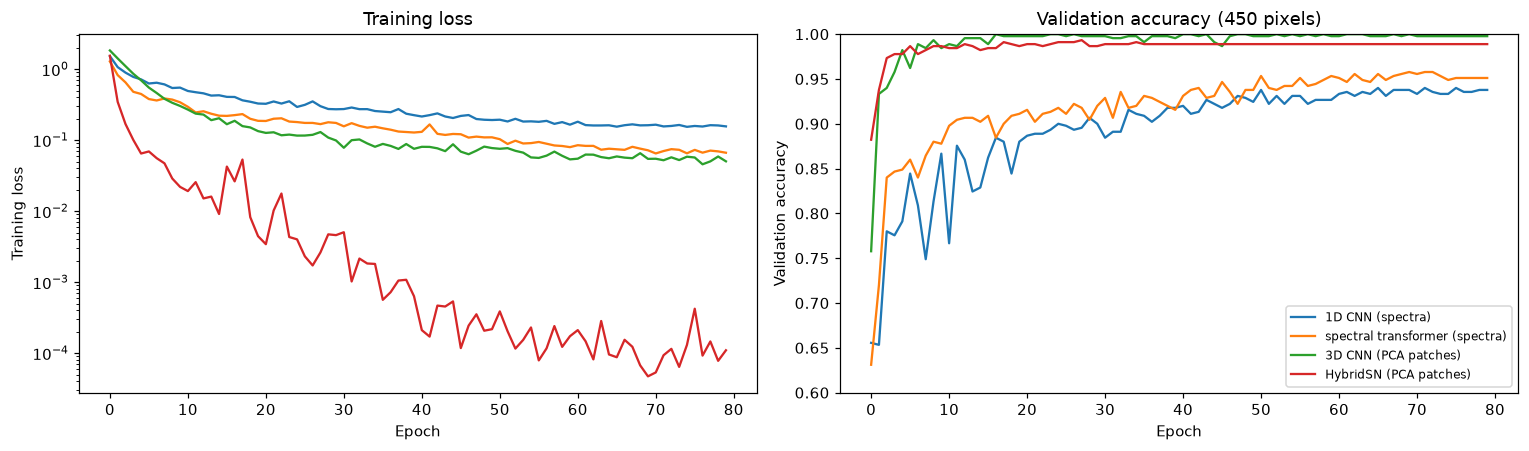

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, h in histories.items():
    axes[0].plot(h["train_loss"], label=name); axes[1].plot(h["val_accuracy"], label=name)
axes[0].set(xlabel="Epoch", ylabel="Training loss", yscale="log", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy (450 pixels)", ylim=(0.6, 1.0))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Comparing the models


In [7]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,overall accuracy,kappa,mean F1,seconds
model,,,,
SAM (class means),0.913,0.884,0.811,1.3
random forest (spectra),0.948,0.930,0.894,1.4
1D CNN (spectra),0.953,0.938,0.909,7.6
spectral transformer (spectra),0.957,0.942,0.911,13.9
3D CNN (PCA patches),0.987,0.982,0.970,13.1
HybridSN (PCA patches),0.991,0.988,0.981,14.4


Read the table in two parts. Among the spectral models the class mean SAM is clearly weakest (overall
accuracy 0.91), the random forest is a strong, fast baseline (0.95), and the 1D CNN and the spectral
transformer improve on it only slightly (about 0.95 to 0.96) with 200 labels per class. The spatial
models, which see an 11 by 11 pixel neighbourhood, are far better on the held-out blocks (about 0.99,
kappa 0.98): context separates classes whose VNIR spectra overlap, as the per class table below shows.

The training curves show two behaviours. HybridSN drives its training loss down to about 10⁻⁴, it
memorises the 1800 training patches, yet its validation accuracy stays near 0.99, so the memorised
features still generalise to new blocks of the same city. The validation pixels come from the training
blocks, so the validation curves (up to 1.0 for the 3D CNN) are more optimistic than the test table.
Pavia Centre at 1.3 m is an easy benchmark for spatial models even with a block split; the gap between
spectral and spatial models, not the absolute numbers, is the transferable lesson.


## Per class results


,SAM (class means),random forest (spectra),1D CNN (spectra),spectral transformer (spectra),3D CNN (PCA patches),HybridSN (PCA patches)
water,0.985,0.994,0.990,0.991,0.998,0.996
trees,0.795,0.915,0.922,0.909,0.968,0.986
meadows,0.711,0.858,0.875,0.867,0.915,0.975
self-blocking bricks,0.568,0.737,0.753,0.757,0.977,0.992
bare soil,0.724,0.792,0.883,0.887,0.958,0.967
asphalt,0.870,0.913,0.867,0.895,0.977,0.989
bitumen,0.861,0.862,0.903,0.905,0.990,0.996
tiles,0.972,0.975,0.986,0.991,0.994,0.995
shadows,0.811,1.000,0.999,0.995,0.950,0.931


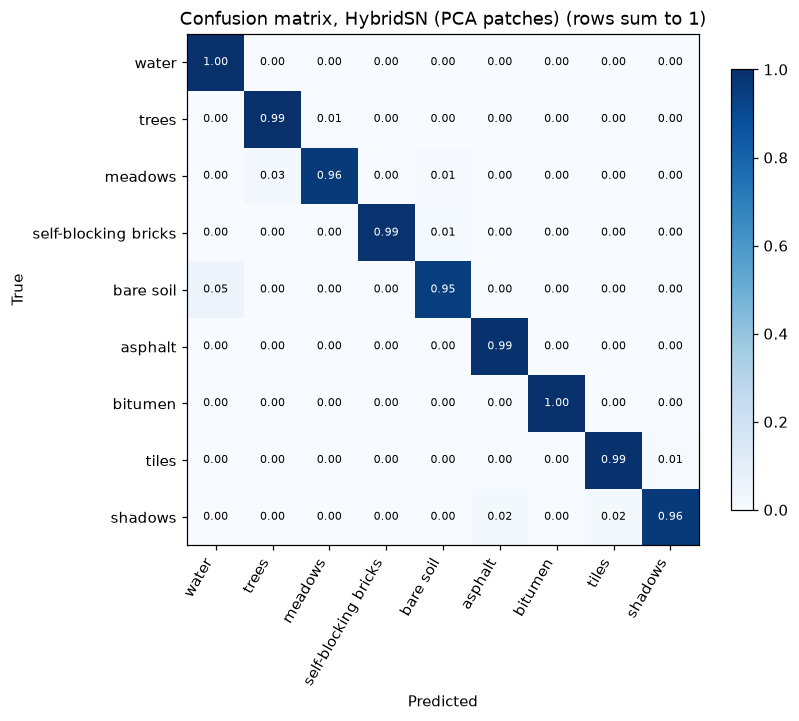

In [8]:
best = res["overall accuracy"].idxmax()
per_class = pd.DataFrame({m: f1_score(y[te], p, average=None, labels=range(1, 10)) for m, p in preds.items()}, index=NAMES)
display(per_class.round(3))
cm = confusion_matrix(y[te], preds[best], labels=range(1, 10), normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(9), NAMES, rotation=60, ha="right"); ax.set_yticks(range(9), NAMES)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if cm[i, j] > 0.5 else "k")
ax.set(xlabel="Predicted", ylabel="True", title=f"Confusion matrix, {best} (rows sum to 1)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

The per class F1 table shows where each model struggles; compare its columns. Water and tiles are easy
for every model. For the spectral models the hard classes are self-blocking bricks (F1 about 0.74 to
0.76), meadows and bare soil; the spatial models lift bricks to about 0.98, because the shape and
neighbourhood of a brick paved area are distinctive even when its spectrum is not. The confusion
matrix of the best model shows what remains: some bare soil is called water (7 percent) and a few
shadow pixels are called asphalt or tiles. Classes with few test pixels can change their scores
noticeably between runs, so small differences between models should not be over interpreted.


## Mapping the city

The best model classifies every pixel of the image; the maximum softmax probability is kept as a
confidence map.


HybridSN (PCA patches): 783,640 pixels classified in 11 s


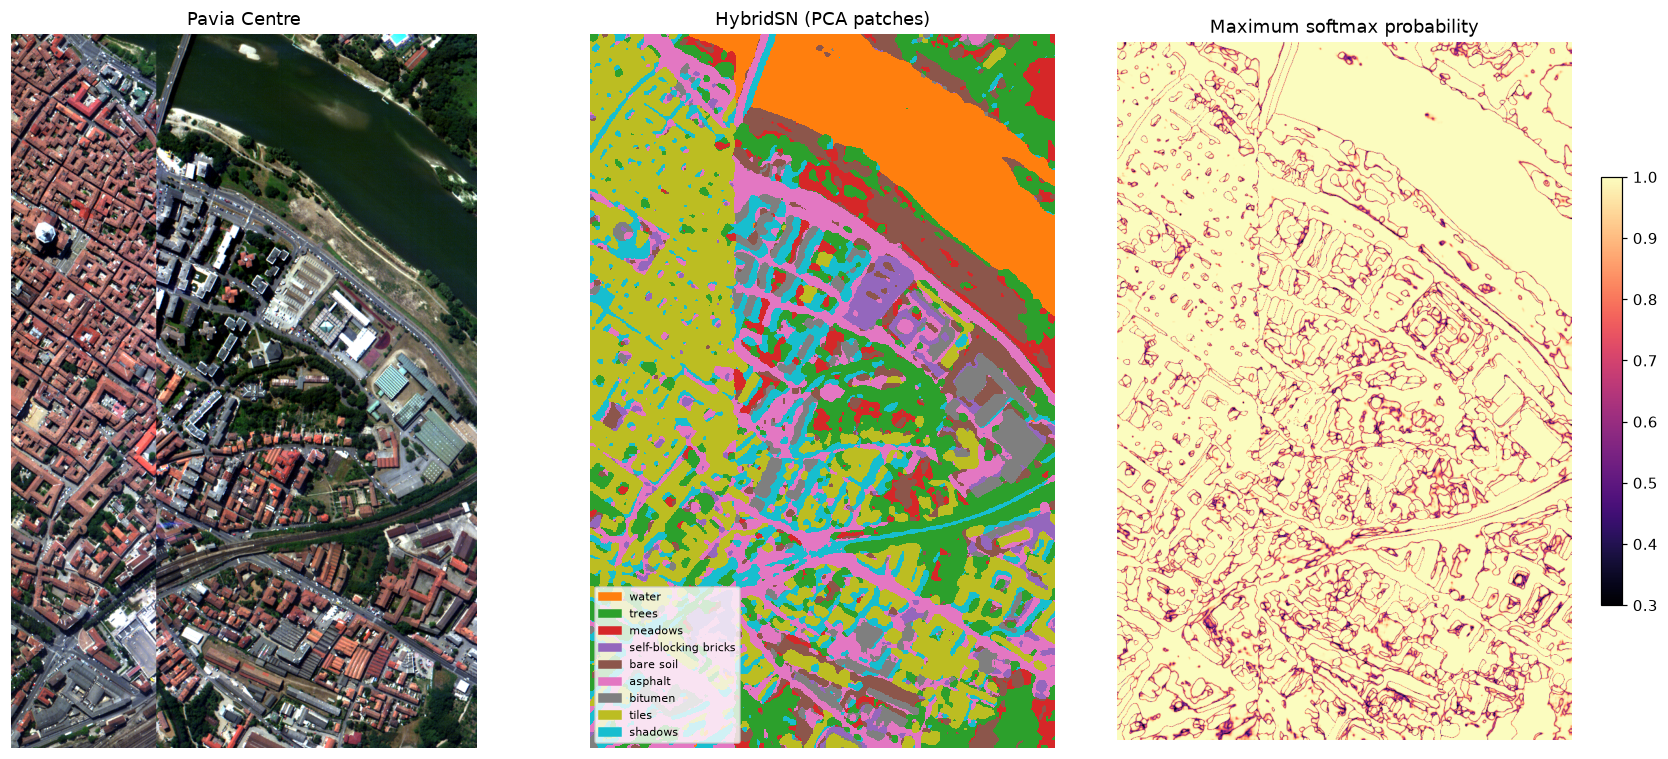

mean confidence: labelled pixels 0.998, unlabelled pixels 0.938


In [9]:
d_tr = models[best][1][0]  # training dataset of the best model (patch size, stats, classes)
cube_best = pcc if "patches" in best else pavia
t0 = time.perf_counter()
cmap_pred, prob = dlh.predict_hsi_map(nets[best], cube_best, d_tr, batch_size=4096, device=DEVICE, proba=True)
print(f"{best}: {cmap_pred.size:,} pixels classified in {time.perf_counter() - t0:.0f} s")
fig, axes = plt.subplots(1, 3, figsize=(16, 7))
hs.plot_rgb(pavia, (640, 550, 460), ax=axes[0], title="Pavia Centre")
axes[1].imshow(cmap_pred, cmap=cmap9, vmin=-0.5, vmax=9.5, interpolation="nearest"); axes[1].set_title(f"{best}")
axes[1].legend(handles=[plt.matplotlib.patches.Patch(color=cmap9(k + 1), label=n) for k, n in enumerate(NAMES)],
               fontsize=7, loc="lower left")
im = axes[2].imshow(prob, cmap="magma", vmin=0.3, vmax=1); axes[2].set_title("Maximum softmax probability")
plt.colorbar(im, ax=axes[2], shrink=0.6)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
unl = gt == 0
print(f"mean confidence: labelled pixels {np.nanmean(prob.values[~unl]):.3f}, unlabelled pixels {np.nanmean(prob.values[unl]):.3f}")

The map extends the nine classes to the whole city, including the unlabelled majority of pixels.
Confidence is high over the river, parks and large roofs and lower along edges, on mixed and small
objects, and on materials that are not among the nine classes (other roof types, vehicles, the
stitching seam); the mean confidence of unlabelled pixels is lower than that of labelled ones. Low
confidence is a useful flag, but softmax probabilities are not calibrated: a network can be confident
and wrong on a material it never saw.


## Summary and exercises

**Key points**

- Spatially blocked splits keep test pixels away from training pixels and give honest accuracies;
  validation pixels from the training blocks are optimistic.
- With 200 labels per class a random forest is a strong spectral baseline (0.95); spectral CNNs and
  transformers add little, while spatial models that see a neighbourhood reach about 0.99 on Pavia.
- Per class scores and the confusion matrix show which materials remain confused (similar VNIR
  spectra), which overall accuracy hides.
- Mapping with the best model gives a full scene map and a confidence layer that flags edges, mixed
  pixels and unknown materials, though softmax confidence is not a calibrated probability.

**`geolattice.rsense.hyperspectral` and `geolattice.rsense.dl.hyperspectral` functions used:** `as_cube`,
`pca`, `classify_spectral`, `library.from_dict`, `plot_rgb`; `block_split`, `HSIPatchDataset`,
`SpectralCNN1D`, `SpectralTransformer`, `CNN3D`, `HybridSN`, `train_hsi_classifier`, `evaluate`,
`predict_hsi_map`.

**Exercises**

1. Repeat the experiment with a random pixel split (`test = gt > 0` minus a random sample) and compare
   the accuracies with the block split. How large is the leakage effect?
2. Train with 50 and 500 pixels per class. Which model gains most from more labels?
3. Feed HybridSN 30 MNF components instead of 20 PCA components (`hs.mnf`).
4. Change the patch size to 7 and 15. What happens to accuracy and to the map along object edges?
5. Train the 3D CNN without augmentation (`augment=False`) and compare the validation curves.
